# Day 2 - Từ annotation YOLO đến detector YOLO26

Notebook này chạy **sau** khi nhãn 50 ảnh train đã qua cổng gold-set. Tập `eval` 10 ảnh không được dùng để train.

Quy trình chuẩn: bạn **fork repo đề bài**, gán nhãn, **commit và push** `dataset/labels/train/` lên repo của mình, rồi chỉ cần dán URL repo vào `REPO_URL` ở cell đầu tiên — Colab sẽ tự clone repo, train và đánh giá, không cần upload file.

Bài cá nhân. Hạn nộp: 11:59 trưa ngày hôm sau buổi lab (UTC+7); ca 09/11/2026 nộp trước 11:59 ngày 10/11/2026.

**Trạng thái bài làm:** gold QC F1=0.5083, mean IoU=0.8542, chưa đạt. Người học yêu cầu chạy thử nghiệm; kết quả model không thay thế điều kiện gold QC.


## Kiểm tra trước khi chạy

- Đã **fork repo đề bài**, gán nhãn và **commit + push** `dataset/labels/train/` lên repo của bạn.
- Ở cell tiếp theo, dán **URL repo của bạn** vào `REPO_URL` — notebook tự clone, không cần upload file.
- Không có `gold_train_labels/` trong repo.
- Chạy từ trên xuống dưới; giữ nguyên `data.yaml` và split eval.
- mAP đo model; F1/IoU ở script trước đó đo chất lượng nhãn con người.

In [1]:
%pip -q install -U ultralytics

from pathlib import Path
import json
import os
import subprocess
import sys
import zipfile
import torch
import yaml
import ultralytics
from ultralytics import YOLO

REPO_URL = 'https://github.com/ducnguyen-ai/K5-L2A-Day02-NguyenCaoNgocDuc-2A202603178-ObjectDetection.git'
REPO_BRANCH = 'main'
LAB_ROOT = (Path('/content/Day2-Lab') if Path('/content').is_dir() else Path('Day2-Lab')).resolve()
env = {**os.environ, 'GIT_TERMINAL_PROMPT': '0'}
if LAB_ROOT.exists():
    origin = subprocess.check_output(['git', '-C', str(LAB_ROOT), 'remote', 'get-url', 'origin'], text=True).strip()
    assert origin.rstrip('/').removesuffix('.git') == REPO_URL.removesuffix('.git'), 'Thư mục đã tồn tại thuộc repo khác.'
    dirty = subprocess.check_output(['git', '-C', str(LAB_ROOT), 'status', '--porcelain'], text=True).strip()
    assert not dirty, 'Có thay đổi chưa lưu trong bản clone; hãy lưu lại trước khi cập nhật.'
    subprocess.run(['git', '-C', str(LAB_ROOT), 'switch', REPO_BRANCH], check=True)
    subprocess.run(['git', '-C', str(LAB_ROOT), 'pull', '--ff-only'], check=True, env=env)
else:
    subprocess.run(['git', 'clone', '--branch', REPO_BRANCH, REPO_URL, str(LAB_ROOT)], check=True, env=env)

SOURCE_COMMIT = subprocess.check_output(['git', '-C', str(LAB_ROOT), 'rev-parse', 'HEAD'], text=True).strip()
TRAIN_IMAGES = LAB_ROOT / 'dataset/images/train'
TRAIN_LABELS = LAB_ROOT / 'dataset/labels/train'
EVAL_IMAGES = LAB_ROOT / 'dataset/images/eval'
EVAL_LABELS = LAB_ROOT / 'dataset/labels/eval'
OUTPUTS = LAB_ROOT / 'outputs'
OUTPUTS.mkdir(exist_ok=True)
RUNS = OUTPUTS / 'yolo26_runs'
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
# Giữ data.yaml gốc; dùng bản runtime có đường dẫn tuyệt đối.
DATA_YAML = OUTPUTS / 'data_colab.yaml'
cfg = yaml.safe_load((LAB_ROOT / 'data.yaml').read_text(encoding='utf-8'))
assert cfg['train'] == 'images/train' and cfg['val'] == 'images/eval'
assert cfg['names'] == {0: 'car', 1: 'truck', 2: 'bus', 3: 'van'}
cfg['path'] = str(LAB_ROOT / 'dataset')
DATA_YAML.write_text(yaml.safe_dump(cfg, allow_unicode=True, sort_keys=False), encoding='utf-8')
RUNTIME = {'source_commit': SOURCE_COMMIT, 'torch': torch.__version__,
           'ultralytics': ultralytics.__version__, 'device': str(DEVICE),
           'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None}
print(json.dumps(RUNTIME, indent=2))


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
{
  "source_commit": "39dee24b7dd833096980eabe2ed38830b2f06a8f",
  "torch": "2.14.1+cu130",
  "ultralytics": "8.4.208",
  "device": "0",
  "gpu": "Tesla T4"
}


In [2]:
def image_stems(directory):
    return {p.stem for ext in ('*.jpg', '*.jpeg', '*.png') for p in directory.glob(ext)}

train_images = image_stems(TRAIN_IMAGES)
eval_images = image_stems(EVAL_IMAGES)
assert len(train_images) == 50 and len(eval_images) == 10
assert train_images.isdisjoint(eval_images), 'Train/eval bị trùng basename.'
for images, labels in ((TRAIN_IMAGES, TRAIN_LABELS), (EVAL_IMAGES, EVAL_LABELS)):
    subprocess.run([sys.executable, str(LAB_ROOT / 'tools/check_yolo_labels.py'),
                    '--images', str(images), '--labels', str(labels)], check=True)

# Người học yêu cầu chạy thử nghiệm dù gold QC hiện chưa đạt.
# Không đổi kết quả QC và không coi lần chạy này là đạt CP5.
ALLOW_EXPERIMENT_WITH_FAILED_QC = True
qc_path = OUTPUTS / 'annotation_evaluation.json'
assert qc_path.is_file(), 'Thiếu annotation_evaluation.json; chỉ đưa JSON kết quả lên repo, không đưa gold train.'
QC = json.loads(qc_path.read_text(encoding='utf-8'))
QC_PASSED = (QC.get('passed') is True and QC['f1'] >= 0.80
             and QC['mean_iou_of_matches'] >= 0.70 and len(QC.get('per_image', [])) == 50)
assert QC_PASSED or ALLOW_EXPERIMENT_WITH_FAILED_QC, 'Cần sửa nhãn trước khi train.'
if not QC_PASSED:
    print('THỬ NGHIỆM: gold QC chưa đạt; không xác nhận hoàn thành CP5.',
          'F1:', QC['f1'], 'mean IoU:', QC['mean_iou_of_matches'])
print('OK: 50 train + 10 eval; eval chỉ dùng validation/đánh giá.')


THỬ NGHIỆM: gold QC chưa đạt; không xác nhận hoàn thành CP5. F1: 0.5083 mean IoU: 0.8542
OK: 50 train + 10 eval; eval chỉ dùng validation/đánh giá.


## Huấn luyện

Bài thực hành dùng checkpoint `yolo26n.pt`. Với 50 ảnh, dùng model nano và ít epoch để minh họa vòng lặp dữ liệu; thời gian/metric không dùng làm benchmark sản phẩm.

In [3]:
model = YOLO('yolo26n.pt')
train_result = model.train(
    data=str(DATA_YAML),
    epochs=50,
    imgsz=640,
    batch=-1 if DEVICE != 'cpu' else 8,
    device=DEVICE,
    project=str(RUNS),
    name='vehicle_annotation',
    exist_ok=True,
    seed=20260909,
    plots=True,
    workers=2,
)
BEST = Path(model.trainer.best)
print('best checkpoint:', BEST)

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Day2-Lab/outputs/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=vehicle_annotation, nbs=64, nms=None, opset=Non

## Đánh giá đúng tập eval

`data.yaml` trỏ `val` tới 10 ảnh eval đã có nhãn. Không đổi `val` sang train để làm đẹp mAP. Ghi lại mAP50, mAP50-95, precision và recall.

Tập `eval` cũng được dùng làm validation trong quá trình train và chọn `best.pt`, nên không phải test set độc lập.

In [4]:
best_model = YOLO(str(BEST))
metrics = best_model.val(data=str(DATA_YAML), split='val', device=DEVICE, plots=True, project=str(RUNS), name='vehicle_eval', exist_ok=True)
summary = {
    'runtime': RUNTIME,
    'annotation_qc_passed': QC_PASSED,
    'experimental_run': not QC_PASSED,
    'per_class': [{'class_id': int(c), 'name': best_model.names[int(c)],
                   'precision': float(metrics.box.p[i]), 'recall': float(metrics.box.r[i]),
                   'map50': float(metrics.box.ap50[i]), 'map50_95': float(metrics.box.ap[i])}
                  for i, c in enumerate(metrics.box.ap_class_index)],
    'precision': float(metrics.box.mp),
    'recall': float(metrics.box.mr),
    'map50': float(metrics.box.map50),
    'map50_95': float(metrics.box.map),
    'eval_images': len(eval_images),
    'checkpoint': str(BEST),
}
metrics_path = LAB_ROOT / 'outputs/model_eval_metrics.json'
metrics_path.parent.mkdir(parents=True, exist_ok=True)
metrics_path.write_text(json.dumps(summary, indent=2) + '\n')
print(json.dumps(summary, indent=2))

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1566.2±506.0 MB/s, size: 76.8 KB)
val: Scanning /content/Day2-Lab/dataset/labels/eval.cache... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 2.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 5.6it/s 0.2s
                   all         10        113      0.188      0.467      0.305      0.201
                   car         10         94      0.197      0.915      0.716      0.467
                 truck          5          5      0.503      0.203      0.445      0.303
                   bus          2          2    0.00496        0.5      0.033     0.0231
                   van          6         12     0.0475       0.25      0.024      0.012
Speed: 0.4ms preprocess, 3.5ms inference, 0

In [5]:
prediction_dir = OUTPUTS / 'eval_predictions'
results = best_model.predict(source=str(EVAL_IMAGES), conf=0.25, device=DEVICE,
                             save=True, project=str(prediction_dir), name='visuals', exist_ok=True)
assert len(results) == 10, 'Cần đủ 10 ảnh prediction.'
PRED_SAVE_DIR = Path(results[0].save_dir)
# Chỉ đóng gói log, ảnh và metrics; không chứa checkpoint, gold hay ZIP lồng nhau.
archive = OUTPUTS / 'day2_colab_outputs.zip'
with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as z:
    for root in (prediction_dir, RUNS):
        for file in sorted(root.rglob('*')):
            if file.is_file() and file.suffix.lower() in {'.png', '.jpg', '.jpeg', '.csv', '.yaml', '.json', '.txt'}:
                z.write(file, Path('day2_colab_outputs') / file.relative_to(OUTPUTS))
    z.write(metrics_path, 'day2_colab_outputs/model_eval_metrics.json')
print('Đã tạo:', archive)
from IPython.display import FileLink, display
display(FileLink(str(archive)))



image 1/10 /content/Day2-Lab/dataset/images/eval/drive_051.jpg: 640x640 36 cars, 9 buss, 2 vans, 50.0ms
image 2/10 /content/Day2-Lab/dataset/images/eval/drive_052.jpg: 640x640 41 cars, 3 buss, 3 vans, 47.9ms
image 3/10 /content/Day2-Lab/dataset/images/eval/drive_053.jpg: 640x640 26 cars, 4 buss, 39.1ms
image 4/10 /content/Day2-Lab/dataset/images/eval/drive_054.jpg: 640x640 15 cars, 2 buss, 4 vans, 30.2ms
image 5/10 /content/Day2-Lab/dataset/images/eval/drive_055.jpg: 640x640 25 cars, 3 buss, 1 van, 15.4ms
image 6/10 /content/Day2-Lab/dataset/images/eval/drive_056.jpg: 640x640 45 cars, 16 buss, 9 vans, 25.3ms
image 7/10 /content/Day2-Lab/dataset/images/eval/drive_057.jpg: 640x640 47 cars, 30 buss, 1 van, 41.3ms
image 8/10 /content/Day2-Lab/dataset/images/eval/drive_058.jpg: 640x640 67 cars, 23 buss, 9 vans, 43.2ms
image 9/10 /content/Day2-Lab/dataset/images/eval/drive_059.jpg: 640x640 11 cars, 1 bus, 1 van, 48.7ms
image 10/10 /content/Day2-Lab/dataset/images/eval/drive_060.jpg: 640x640

/content/Day2-Lab/outputs/day2_colab_outputs.zip

## Xem trực tiếp kết quả dự đoán

Hiển thị 10 ảnh eval kèm box dự đoán ngay trong notebook, không cần tải file `.zip` về mới xem được.

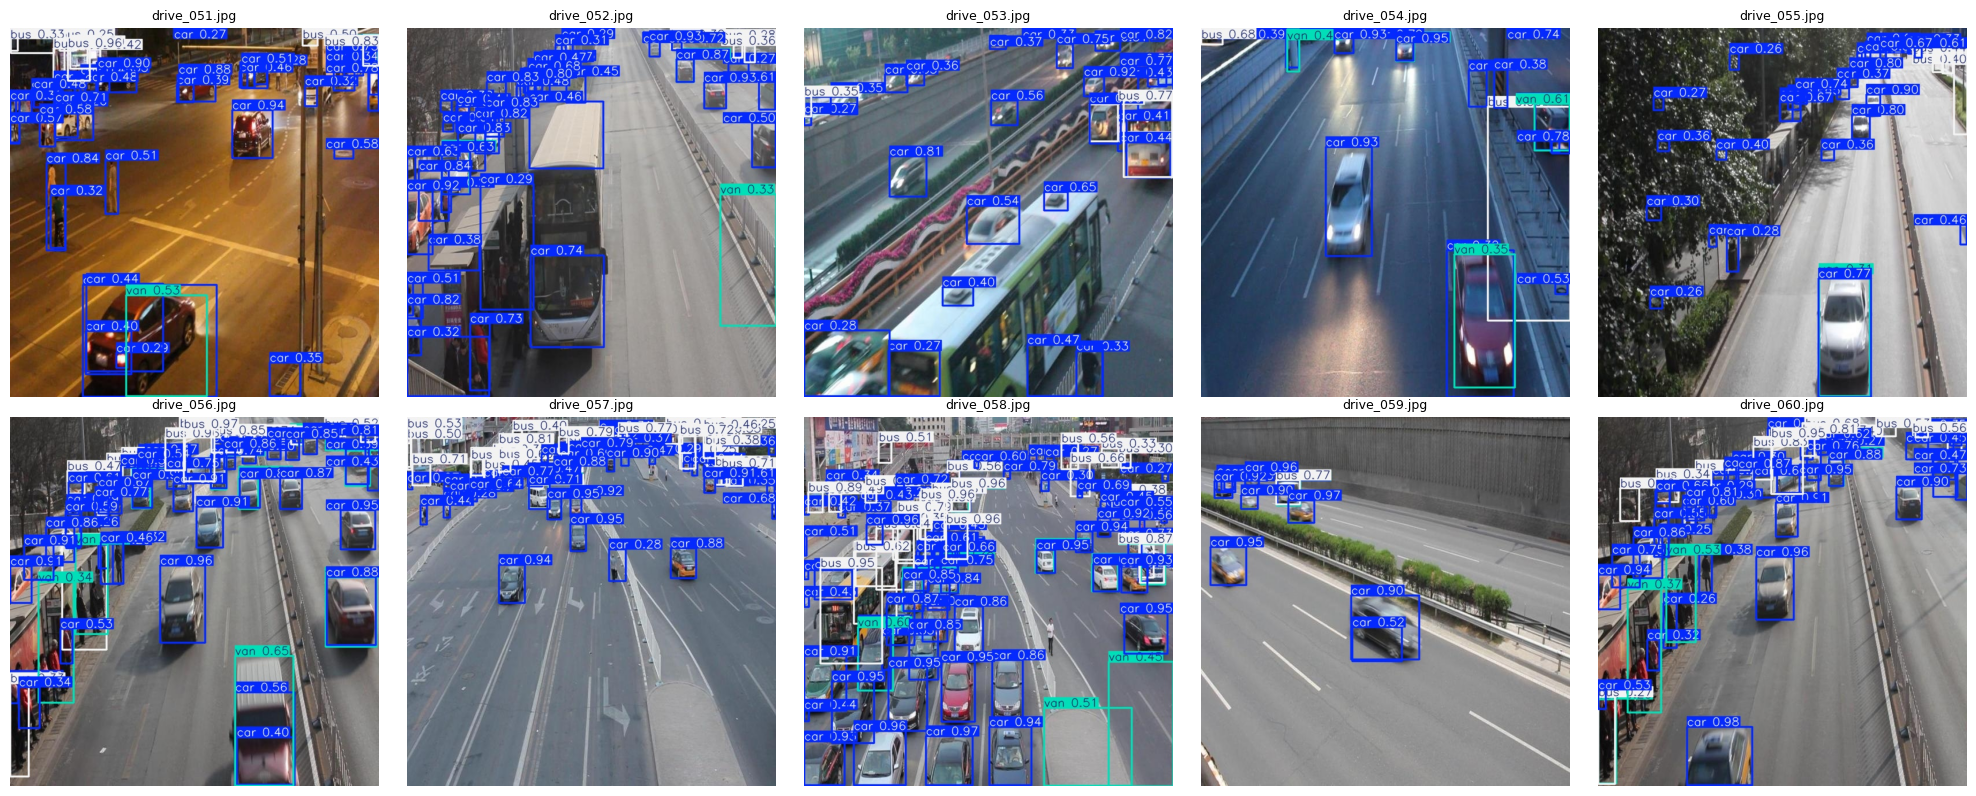

In [6]:
import math
import matplotlib.pyplot as plt
from PIL import Image

pred_images = sorted(PRED_SAVE_DIR.glob('*.jpg'))
cols = 5
rows = math.ceil(len(pred_images) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
for ax, img_path in zip(axes.flat, pred_images):
    ax.imshow(Image.open(img_path))
    ax.set_title(img_path.name, fontsize=9)
    ax.axis('off')
for ax in axes.flat[len(pred_images):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Câu hỏi phân tích để nộp

1. Lớp nào có recall thấp nhất? Chỉ ra một ảnh eval minh họa.
2. Nếu mAP50 cao nhưng mAP50-95 thấp, box đang gặp vấn đề gì?
3. Có lỗi `truck`/`bus`/`van`/`car` nào liên quan tới guideline không?
4. Vì sao không dùng 10 ảnh eval để train dù chúng có nhãn?